# Exercise: Cross-Validation and Classifier Comparison on Imbalanced Data


In this exercise, you will:

- Use 5-fold cross-validation to evaluate the performance of several classifiers on an imbalanced dataset.

- Compare the classifiers using accuracy and F1-score metrics.
Understand why accuracy can be misleading on imbalanced datasets and explore different classifier parameters.

a) Load and Explore the Dataset: We’ll use the Credit Card Fraud Detection dataset from Scikit-Learn, which has a binary classification target and is highly imbalanced.

In this dataset, the target variable (Class) has two classes: 1 indicates fraud, and 0 indicates non-fraudulent transactions.

b) Define Cross-Validation and Performance Metrics: Use 5-fold cross-validation to evaluate each classifier.

c) Calculate accuracy and F1-score to assess model performance.

d) Use the following classifiers:
- Naïve Bayes
- k-Nearest Neighbors (k-NN)
- Support Vector Machine (SVM)
- Decision Tree

For each classifier, try adjusting key parameters and observe the effect on performance metrics.

e) Analyze the Results:
- Compare accuracy and F1-score for each classifier.
- Why might accuracy be misleading on this imbalanced dataset?
- Which classifier performed best on F1-score, and why might this be a better metric here?
- How did different parameter settings (e.g., k in k-NN, C in SVM) affect performance?

In [1]:
from sklearn.datasets import fetch_openml

# Load the imbalanced dataset
data = fetch_openml(name="creditcard", version=1, as_frame=True)

In [2]:
print(data['DESCR'])

**Author**: Andrea Dal Pozzolo, Olivier Caelen and Gianluca Bontempi  
**Source**: Credit card fraud detection - Date 25th of June 2015  
**Please cite**: Andrea Dal Pozzolo, Olivier Caelen, Reid A. Johnson and Gianluca Bontempi. Calibrating Probability with Undersampling for Unbalanced Classification. In Symposium on Computational Intelligence and Data Mining (CIDM), IEEE, 2015  

The datasets contains transactions made by credit cards in September 2013 by european cardholders. This dataset present transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, ... V28 are the principal components obtained with PCA, th

### Exercise Resolution

a) Load and Explore the Dataset: We'll use the Credit Card Fraud Detection from Scikit-Learn, which has a binary classification target and is highly imbalanced

Let's brake a little down inside the dataset given

In [18]:
X = data['data']
y = data['target'].astype(int)

print(X.shape, y.shape)
X.head()

(284807, 29) (284807,)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


Class distribution

In [19]:
print(y.value_counts())
print(y.value_counts(normalize=True)* 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


Imbalance visualization

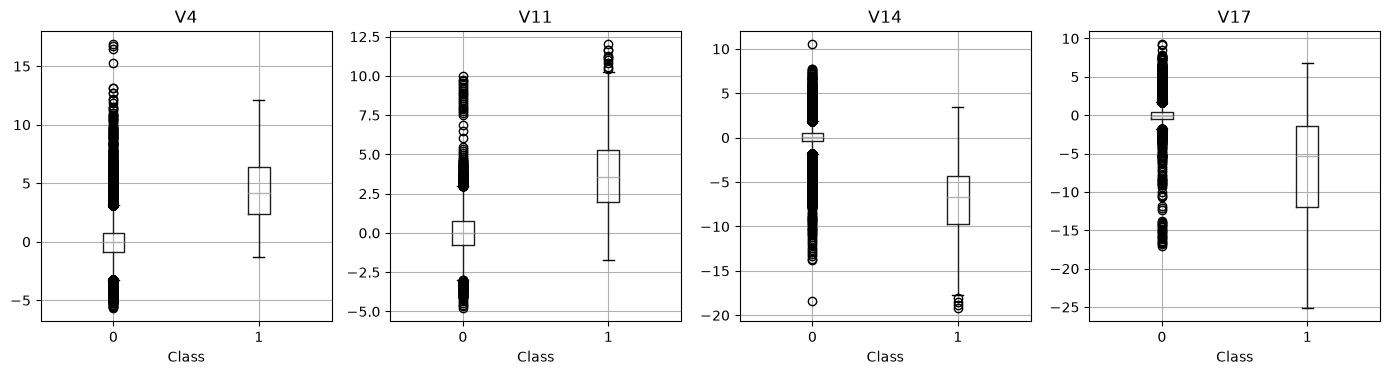

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, ['V4', 'V11', 'V14', 'V17']):
    X.assign(Class=y).boxplot(column=col, by='Class', ax=ax)
plt.suptitle('')
plt.tight_layout()
plt.show()

b) Define Cross-Validation and Performance Metrics: Use 5-fold cross-validation to evaluate each classifier

In [22]:
import numpy as np 
from  sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Now let's define the classifier methods:

- **Naïve Bayes**

- **k-Nearest Neighbor (k-NN)**

- **Support Vector Machine**

- **Decision Tree**

In [23]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

classifiers = {
    "Naïve Bayes": GaussianNB(),
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=1.0),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

scoring = ['accuracy', 'f1']

results = {}

for name, clf in classifiers.items():
    print(f"Valutation of {name}")

    scores = cross_validate(clf, X, y, cv=cv, scoring=scoring)

    results[name] = {
        'accuracy': scores['test_accuracy'].mean(),
        'f1': scores['test_f1'].mean()
    }

for name, metrics in results.items():
    print(f"--- {name} ---")
    print(f"Accuracy media: {metrics['accuracy']:.4f}")
    print(f"F1-score medio: {metrics['f1']:.4f}\n")

Valutation of Naïve Bayes
Valutation of k-NN
Valutation of SVM
Valutation of Decision Tree
--- Naïve Bayes ---
Accuracy media: 0.9779
F1-score medio: 0.1150

--- k-NN ---
Accuracy media: 0.9993
F1-score medio: 0.7554

--- SVM ---
Accuracy media: 0.9987
F1-score medio: 0.4895

--- Decision Tree ---
Accuracy media: 0.9992
F1-score medio: 0.7741



Data visualization with **Support Vectors Margin**

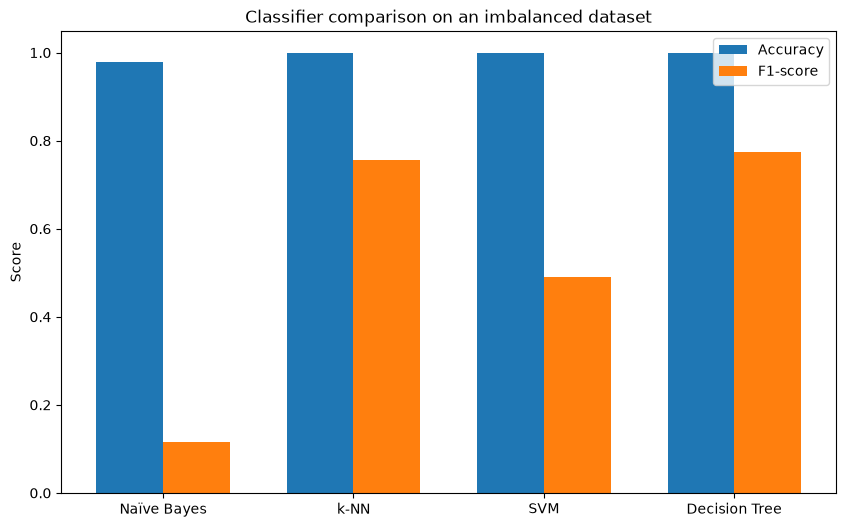

In [30]:
import matplotlib.pyplot as plt


model_names = list(results.keys())
accuracies = [results[m]['accuracy'] for m in model_names]
f1_scores = [results[m]['f1'] for m in model_names]

x = range(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([i - width/2 for i in x], accuracies, width, label='Accuracy')
ax.bar([i + width/2 for i in x], f1_scores, width, label='F1-score')

ax.set_ylabel('Score')
ax.set_title('Classifier comparison on an imbalanced dataset')
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend()

plt.show()